# 06 — Model Evaluation & SHAP Explainability

**Input:** `models/best_model.pkl`, `models/optimal_threshold.pkl`, `data/processed/features.csv`  
**Outputs:** Confusion matrix, ROC curve, SHAP plots in `outputs/`

### Steps covered
1. Load best model and reproduce test split
2. Confusion matrix at optimal threshold
3. ROC curve
4. SHAP global analysis — beeswarm + bar plot
5. SHAP local analysis — waterfall plots for example assets
6. SHAP dependence plots for top 3 features

In [1]:
import pandas as pd
import numpy as np
import pickle
import os
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, average_precision_score
)

RANDOM_STATE = 42
os.makedirs('../outputs', exist_ok=True)
print('Libraries loaded.')

Libraries loaded.


## Step 1 — Load Model and Reproduce Test Split

In [2]:
df = pd.read_csv('../data/processed/features.csv')
y = df['grid_failure_flag']
X = df.drop(columns=['grid_failure_flag'])

_, X_test, _, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

with open('../models/best_model.pkl', 'rb') as f:
    model = pickle.load(f)
with open('../models/optimal_threshold.pkl', 'rb') as f:
    OPTIMAL_THRESHOLD = pickle.load(f)

y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= OPTIMAL_THRESHOLD).astype(int)

print(f'Model type:        {type(model).__name__}')
print(f'Optimal threshold: {OPTIMAL_THRESHOLD:.4f}')
print(f'Test set size:     {len(X_test)}')

Model type:        LGBMClassifier
Optimal threshold: 0.4652
Test set size:     10000


## Step 2 — Confusion Matrix

The four cells explained in business terms:
- **True Positive:** Caught failure → preventive maintenance action taken ✅
- **False Positive:** Unnecessary inspection → ~$1,500 per asset wasted
- **False Negative:** Missed failure → unplanned outage, $250K+ in losses ⚠️ minimize this
- **True Negative:** Correctly identified safe asset → no action needed ✅

=== Confusion Matrix Analysis ===
True Positives  (caught failures):      3,602
False Positives (unnecessary checks):     981  (~$1,471,500 in inspection costs)
False Negatives (MISSED failures):        699  ← minimize this
True Negatives  (correct no-failure):   4,718

Recall (failure detection rate): 0.8375
Precision (of flagged, % actual fail):  0.7859


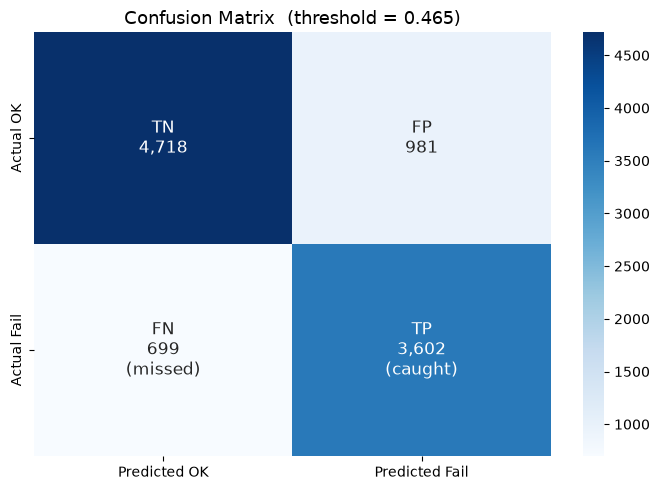

In [3]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print('=== Confusion Matrix Analysis ===')
print(f'True Positives  (caught failures):      {tp:>5,}')
print(f'False Positives (unnecessary checks):   {fp:>5,}  (~${fp*1500:,.0f} in inspection costs)')
print(f'False Negatives (MISSED failures):      {fn:>5,}  ← minimize this')
print(f'True Negatives  (correct no-failure):   {tn:>5,}')
print(f'\nRecall (failure detection rate): {tp/(tp+fn):.4f}')
print(f'Precision (of flagged, % actual fail):  {tp/(tp+fp):.4f}')

fig, ax = plt.subplots(figsize=(7, 5))
labels = np.array([[f'TN\n{tn:,}', f'FP\n{fp:,}'],
                    [f'FN\n{fn:,}\n(missed)', f'TP\n{tp:,}\n(caught)']])
sns.heatmap(cm, annot=labels, fmt='', cmap='Blues',
            xticklabels=['Predicted OK', 'Predicted Fail'],
            yticklabels=['Actual OK', 'Actual Fail'], ax=ax,
            annot_kws={'size': 12})
ax.set_title(f'Confusion Matrix  (threshold = {OPTIMAL_THRESHOLD:.3f})', fontsize=13)
plt.tight_layout()
plt.savefig('../outputs/confusion_matrix.png', dpi=150)
plt.show()

## Step 3 — ROC Curve

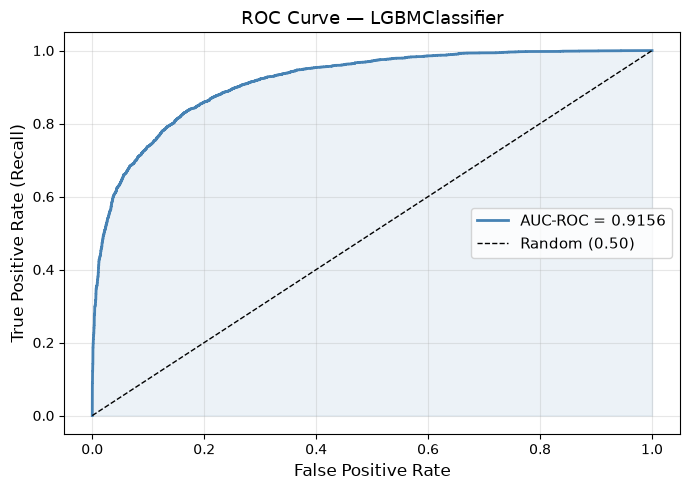

AUC-ROC: 0.9156  |  AUC-PR: 0.8982


In [4]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
auc_pr = average_precision_score(y_test, y_prob)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr, tpr, color='steelblue', linewidth=2, label=f'AUC-ROC = {auc:.4f}')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (0.50)')
ax.fill_between(fpr, tpr, alpha=0.1, color='steelblue')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate (Recall)', fontsize=12)
ax.set_title(f'ROC Curve — {type(model).__name__}', fontsize=13)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/roc_curve.png', dpi=150)
plt.show()
print(f'AUC-ROC: {auc:.4f}  |  AUC-PR: {auc_pr:.4f}')

## Step 4 — Global SHAP Analysis

SHAP (SHapley Additive exPlanations) explains each prediction by assigning a contribution score to every feature for every individual asset.  

**Beeswarm plot:** Each dot = one asset. X-axis = SHAP value (positive pushes toward failure prediction). Color = feature value (red = high, blue = low).  
Features ordered top-to-bottom by mean absolute importance.

In [5]:
# Sample 2000 rows for speed
sample = X_test.sample(n=min(2000, len(X_test)), random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(sample)

# For binary classification, take values for class 1 (failure)
if isinstance(shap_values, list):
    sv = shap_values[1]
    base_val = explainer.expected_value[1]
else:
    sv = shap_values
    base_val = explainer.expected_value

print(f'SHAP values shape: {sv.shape}')
print(f'Base value (log-odds of failure): {base_val:.4f}')

SHAP values shape: (2000, 40)
Base value (log-odds of failure): 0.1134


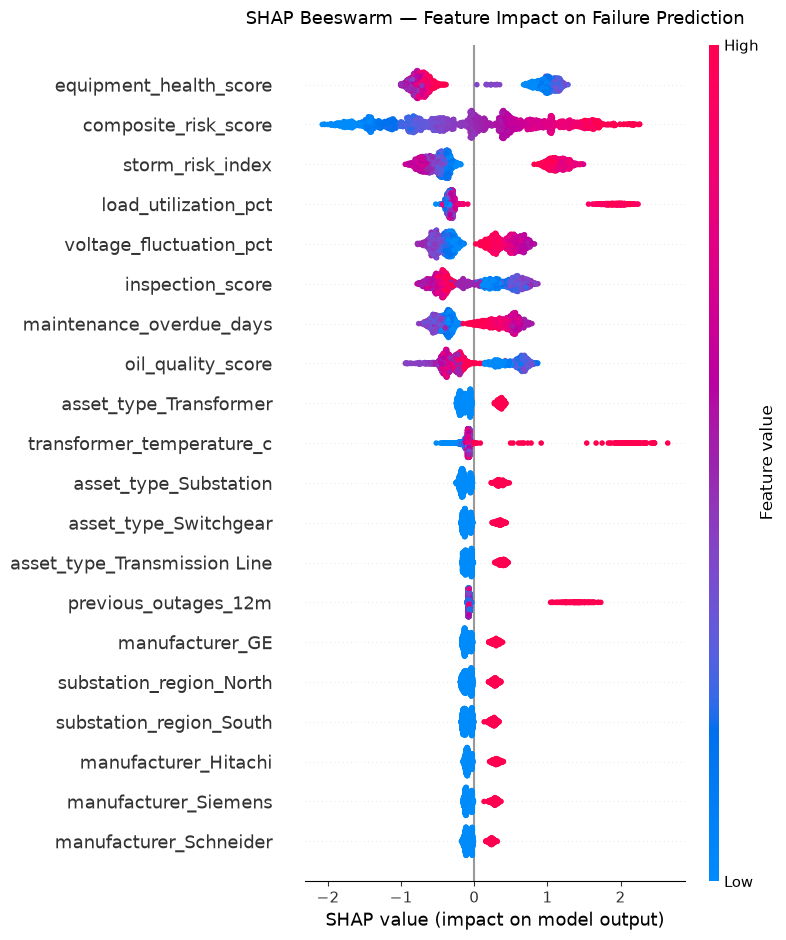

Saved: outputs/shap_beeswarm.png


In [6]:
# Beeswarm plot
plt.figure(figsize=(10, 8))
shap.summary_plot(sv, sample, show=False, max_display=20)
plt.title('SHAP Beeswarm — Feature Impact on Failure Prediction', fontsize=13, pad=15)
plt.tight_layout()
plt.savefig('../outputs/shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: outputs/shap_beeswarm.png')

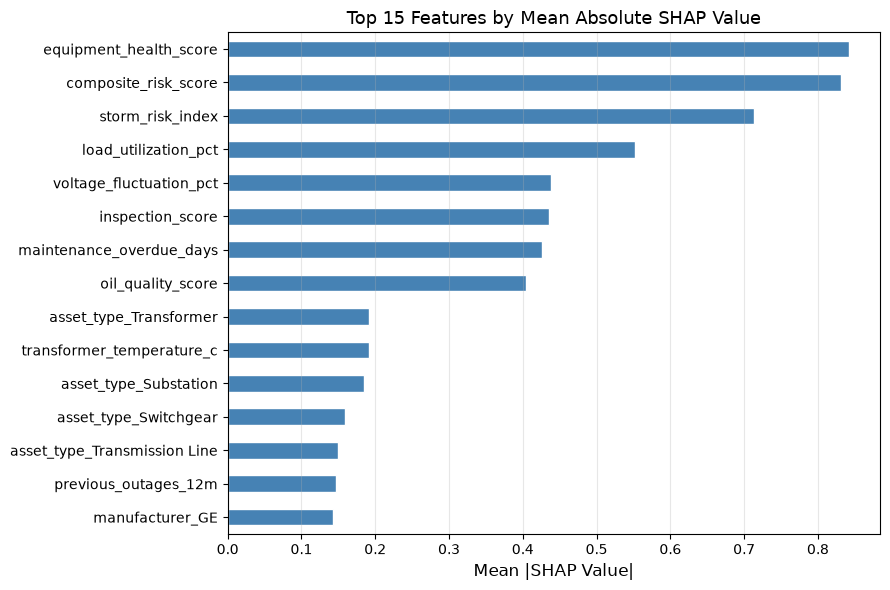


Top 10 failure drivers:
equipment_health_score       0.8420
composite_risk_score         0.8311
storm_risk_index             0.7130
load_utilization_pct         0.5515
voltage_fluctuation_pct      0.4387
inspection_score             0.4361
maintenance_overdue_days     0.4259
oil_quality_score            0.4046
asset_type_Transformer       0.1920
transformer_temperature_c    0.1917
Saved: outputs/shap_bar.png


In [7]:
# Bar plot — mean absolute SHAP (single number per feature)
mean_abs_shap = pd.Series(
    np.abs(sv).mean(axis=0),
    index=sample.columns
).sort_values(ascending=False)

top_n = 15
fig, ax = plt.subplots(figsize=(9, 6))
mean_abs_shap.head(top_n).sort_values().plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_xlabel('Mean |SHAP Value|', fontsize=12)
ax.set_title(f'Top {top_n} Features by Mean Absolute SHAP Value', fontsize=13)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/shap_bar.png', dpi=150)
plt.show()

print(f'\nTop 10 failure drivers:')
print(mean_abs_shap.head(10).round(4).to_string())
print('Saved: outputs/shap_bar.png')

## Step 5 — Local SHAP: Waterfall Plots

Waterfall plots show **why the model made a specific prediction** for a single asset.  
Each bar shows one feature's contribution — pushing right (toward failure) or left (toward safe).

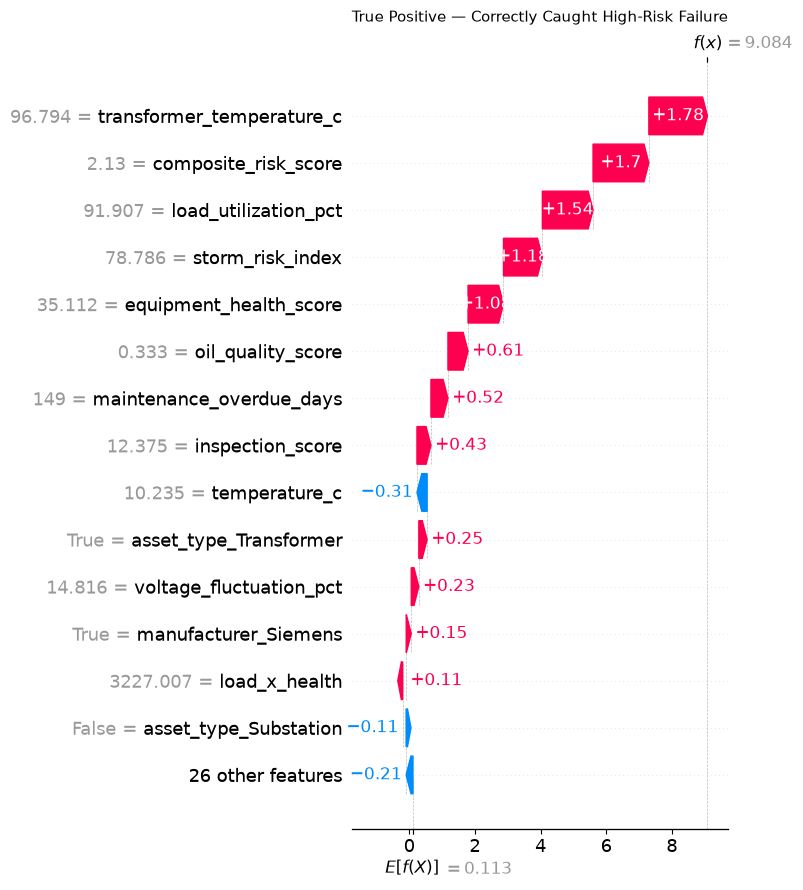

Saved: outputs/shap_waterfall_true_positive.png
  Asset failure probability: 0.9999


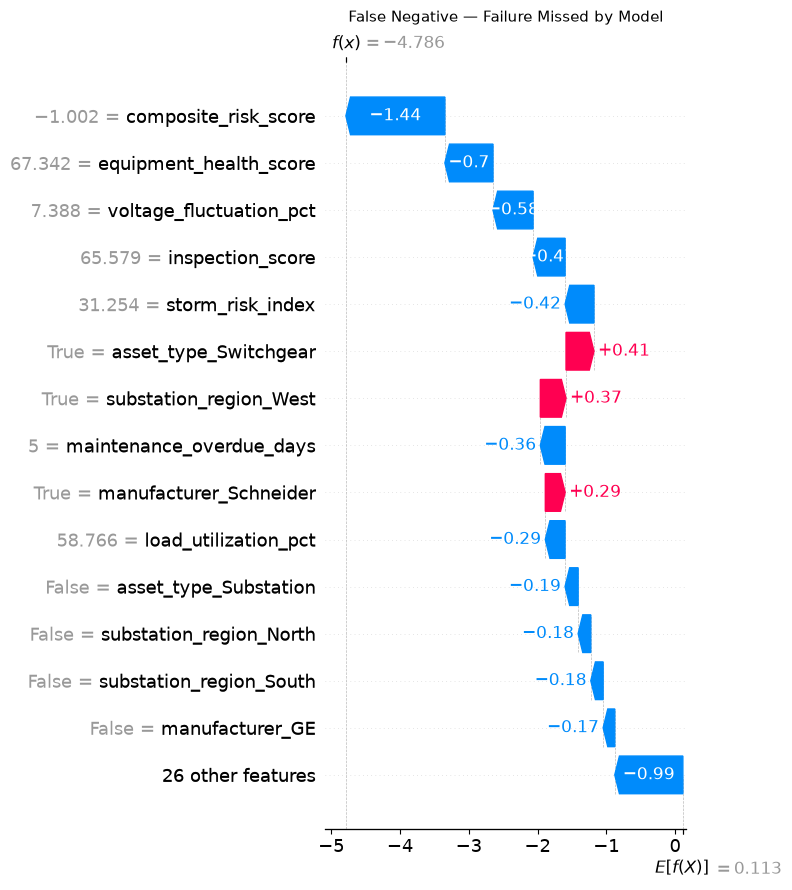

Saved: outputs/shap_waterfall_false_negative.png
  Asset failure probability: 0.0083


In [8]:
# Identify example assets from test set
X_test_eval = X_test.copy()
X_test_eval['actual'] = y_test.values
X_test_eval['prob']   = y_prob
X_test_eval['pred']   = y_pred

# True Positive: caught failure with highest confidence
tp_idx = X_test_eval[
    (X_test_eval['actual'] == 1) & (X_test_eval['pred'] == 1)
].nlargest(1, 'prob').index[0]

# False Negative: failure the model missed (lowest confidence failures)
fn_idx = X_test_eval[
    (X_test_eval['actual'] == 1) & (X_test_eval['pred'] == 0)
].nsmallest(1, 'prob').index[0]

examples = [
    ('True Positive — Correctly Caught High-Risk Failure', tp_idx),
    ('False Negative — Failure Missed by Model', fn_idx)
]

for label, idx in examples:
    row = X_test.loc[[idx]]
    sv_single = explainer.shap_values(row)
    if isinstance(sv_single, list):
        sv_s = sv_single[1][0]
        bv = explainer.expected_value[1]
    else:
        sv_s = sv_single[0]
        bv = explainer.expected_value

    exp = shap.Explanation(
        values=sv_s,
        base_values=bv,
        data=row.iloc[0].values,
        feature_names=X_test.columns.tolist()
    )
    plt.figure(figsize=(10, 6))
    shap.waterfall_plot(exp, max_display=15, show=False)
    plt.title(label, fontsize=11, pad=10)
    plt.tight_layout()
    fname = label.split('—')[0].strip().lower().replace(' ', '_')
    plt.savefig(f'../outputs/shap_waterfall_{fname}.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: outputs/shap_waterfall_{fname}.png')
    print(f'  Asset failure probability: {X_test_eval.loc[idx, "prob"]:.4f}')

## Step 6 — SHAP Dependence Plots (Top 3 Features)

Shows how the SHAP value of each feature changes across its range, and how a second feature (automatically chosen for highest interaction) modulates that relationship.

Generating dependence plots for: ['equipment_health_score', 'composite_risk_score', 'storm_risk_index']


<Figure size 800x500 with 0 Axes>

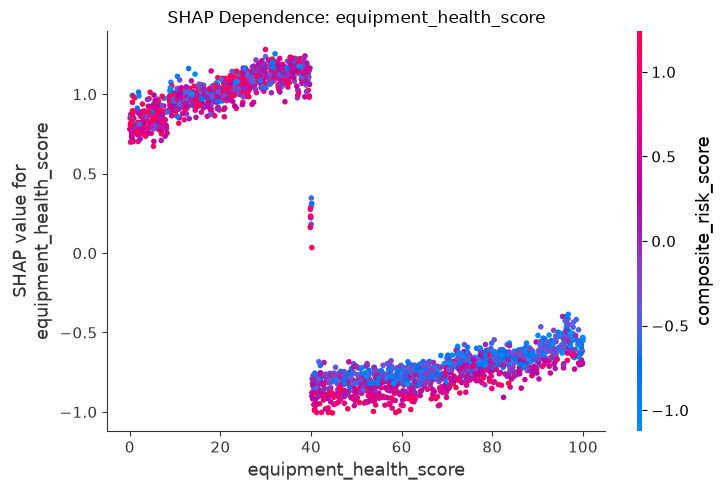

Saved: outputs/shap_dependence_equipment_health_score.png


<Figure size 800x500 with 0 Axes>

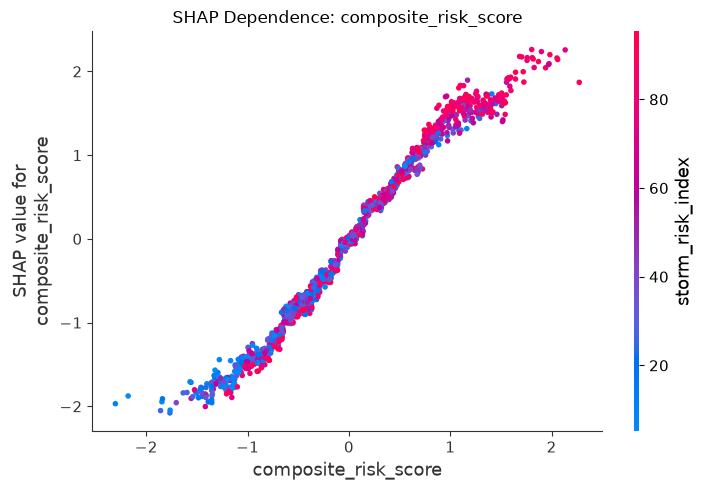

Saved: outputs/shap_dependence_composite_risk_score.png


<Figure size 800x500 with 0 Axes>

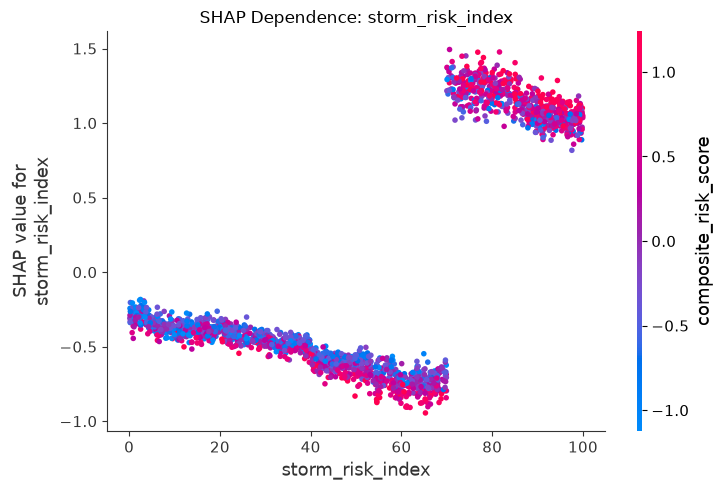

Saved: outputs/shap_dependence_storm_risk_index.png


In [9]:
top_3 = mean_abs_shap.head(3).index.tolist()
print(f'Generating dependence plots for: {top_3}')

for feat in top_3:
    plt.figure(figsize=(8, 5))
    shap.dependence_plot(feat, sv, sample, show=False)
    plt.title(f'SHAP Dependence: {feat}', fontsize=12)
    plt.tight_layout()
    safe_name = feat.replace(' ', '_').replace('/', '_')
    plt.savefig(f'../outputs/shap_dependence_{safe_name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: outputs/shap_dependence_{safe_name}.png')

## Step 7 — Summary

In [10]:
from sklearn.metrics import recall_score, precision_score, f1_score

print('=== Final Evaluation Summary ===')
print(f'Model:             {type(model).__name__}')
print(f'Threshold:         {OPTIMAL_THRESHOLD:.4f}')
print(f'Recall:            {recall_score(y_test, y_pred):.4f}')
print(f'Precision:         {precision_score(y_test, y_pred):.4f}')
print(f'F1:                {f1_score(y_test, y_pred):.4f}')
print(f'AUC-ROC:           {auc:.4f}')
print(f'AUC-PR:            {auc_pr:.4f}')
print(f'True Positives:    {tp}')
print(f'False Negatives:   {fn}  (missed failures)')
print(f'\nTop 5 failure drivers (SHAP):')
print(mean_abs_shap.head(5).round(4).to_string())

=== Final Evaluation Summary ===
Model:             LGBMClassifier
Threshold:         0.4652
Recall:            0.8375
Precision:         0.7859
F1:                0.8109
AUC-ROC:           0.9156
AUC-PR:            0.8982
True Positives:    3602
False Negatives:   699  (missed failures)

Top 5 failure drivers (SHAP):
equipment_health_score     0.8420
composite_risk_score       0.8311
storm_risk_index           0.7130
load_utilization_pct       0.5515
voltage_fluctuation_pct    0.4387
